# The power of quantum neural networks: a reproduction walkthrough

Abbas, Sutter, Zoufal, Lucchi, Figalli, Woerner, *Nature Computational Science* 1, 403-409 (2021),
[arXiv:2011.00027](https://arxiv.org/abs/2011.00027). Reference code:
[amyami187/effective_dimension](https://github.com/amyami187/effective_dimension) (v1.0.0).

This notebook presents the reproduction as a scientific argument: what the paper claims, how we
tested it, what survived, and what did not. It mixes two kinds of evidence, labelled throughout:

- **Live**: computed in this notebook from `lib/` (the whole notebook runs in under a minute on a laptop CPU).
- **Stored**: loaded from `results/notebook_data.json`, a curated export of the full runs
  (`utils/export_notebook_data.py`; each block names its source run directory). Full runs take
  minutes to tens of minutes each and are listed in `README.md`.

It also separates four kinds of work:

| Label | Meaning |
|---|---|
| **Reproduction** | the paper's own experiment, with the paper's settings |
| **Control / ablation** | a change that tests an alternative explanation (parameter domain, init, tuning) |
| **Fair comparison** | the paper's comparison redone with per-model tuning and held-out data (Phase 05) |
| **Extension** | something the paper did not do: new tasks, the photonic (MerLin) adaptation |

## 1. Problem statement and paper claim

**The paper's question.** Can a quantum neural network (QNN) be more *powerful* than a classical
neural network of the same size? The paper measures power in two ways:

1. **Capacity**: the *effective dimension*, a number built from the Fisher information matrix that
   counts how many parameter directions really change the model's output distribution. The paper
   links it to a generalization bound.
2. **Trainability**: how fast the training loss falls on a real task (Iris).

**Claims tested here** (IDs as in `LOG.md`):

| ID | Claim | Paper evidence |
|---|---|---|
| C-01 | At d = 40 parameters, the QNN has a higher normalized effective dimension than the "easy" quantum model and a classical network, for all n in [1e3, 1e6] | Fig. 3a |
| C-02 | The QNN Fisher spectrum is the most uniform; the classical one is degenerate | Fig. 2 |
| C-03 | The QNN resists barren plateaus as the number of qubits grows | Fig. 9, Sec. 4.3 |
| C-04 | At d = 8 on Iris, the QNN reaches the lowest training loss | Fig. 3b, Table 1 |
| C-05 | The QNN's Fisher-Rao norm is about 250% higher | Table 1 |

**Falsifiable research question.** *Does the QNN keep its capacity and trainability lead over
classical models once every model is compared under the same, fairly tuned conditions?*

**What would weaken the claims.**
- C-01/C-02: the ordering fails at some n, or depends on the parameter domain or classical
  topology.
- C-03: the *unnormalized* Fisher scale vanishes with qubit count even if the normalized shape
  looks stable.
- C-04: a classical network with the same parameter count reaches a lower loss once its learning
  rate is tuned the same way as the QNN's.
- C-05: the norm ordering changes with the initialization range (then it measures the
  parameter scale, not capacity).

In [1]:
import json
import math
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch

PROJECT = Path.cwd().resolve()  # papers/power_of_QNN
REPO = PROJECT.parents[1]
for path in (REPO, PROJECT.parent):
    if str(path) not in sys.path:
        sys.path.insert(0, str(path))

from power_of_QNN.lib.data import load_arrays
from power_of_QNN.lib.fisher import effective_dimension
from power_of_QNN.lib.fisher_experiments import fisher_for_draw
from power_of_QNN.lib.models import build_model
from power_of_QNN.lib.training import initial_parameters, per_seed_loss, train

NOTEBOOK_START = time.perf_counter()
DEVICE = torch.device("cpu")  # every live cell runs on CPU in float64
DATA_ROOT = REPO / "data"
STORED = json.loads((PROJECT / "results" / "notebook_data.json").read_text())
COLORS = {
    "qnn": "tab:blue", "Q2": "tab:blue", "Q3": "tab:green", "easy": "tab:cyan",
    "classical": "tab:orange", "linear": "tab:gray", "A8": "tab:purple", "B2": "tab:red",
}


def color_of(name):
    for prefix, value in (("A8", "A8"), ("B2", "B2"), ("Q3", "Q3"), ("Q2", "Q2"), ("easy", "easy"),
                          ("classical_42", "linear"), ("qnn", "qnn"), ("classical", "classical")):
        if name.startswith(prefix):
            return COLORS[value]
    return "black"


def decision(first, second, tolerance=0.005, standard_errors=3.0):
    # The predeclared Phase 05 rule: a gap counts only above max(3 standard errors, 0.005).
    first, second = np.asarray(first), np.asarray(second)
    gap = first.mean() - second.mean()
    threshold = standard_errors * math.sqrt(first.var() / len(first) + second.var() / len(second))
    if abs(gap) <= max(threshold, tolerance):
        return gap, threshold, "no resolved difference"
    return gap, threshold, "first lower (resolved)" if gap < 0 else "second lower (resolved)"


print("torch", torch.__version__, "| numpy", np.__version__, "| stored runs from", STORED["provenance"])

torch 2.12.1 | numpy 2.5.4 | stored runs from utils/export_notebook_data.py from the run directories listed in each block


## 2. Data, splits, metrics, and evaluation protocol

| Task | Used for | Inputs | Splits | Metric |
|---|---|---|---|---|
| Synthetic draws: θ ~ U[0,1]^d, x ~ N(0, I) | effective dimension, Fisher spectra (C-01..C-03) | 4 (or 6/8/10) | 100 θ × 100 x per draw; 5 draws (seeds 0-4) | normalized effective dimension d_{1,n}/d |
| Iris classes 0/1, rows 0:100, L2 row-normalized | Table 1 (C-04, C-05) and fair comparison K1 | 4 | all 100 points are training data (the paper reports training loss) | final training cross-entropy (CE) after 100 iterations |
| Iris 0/1 and Iris 1/2 | fair-comparison extensions X1, X2 | 4 | 30 / 10 / 10 per class (train / validation / test), `RandomState(0)` | test CE; lr selected on validation |
| Breast cancer (Wisconsin), MNIST 3 vs 5 | extensions X3, X4 | 4 PCA components, fit on train only | 341/113/115; 500/500/1,902 | test CE and accuracy |

Data are read from `data/power_of_QNN/` (repository data root) and checked against SHA-256
manifests. Below we load the paper's Iris task and the held-out splits.

In [2]:
cfg_paper = {"data_root": str(DATA_ROOT), "dataset": {"name": "iris_binary"}}
x_iris, y_iris = load_arrays(cfg_paper, "train")
print("Iris 0/1 (paper task):", x_iris.shape, "class counts", np.bincount(y_iris).tolist(),
      "| row norms in [%.3f, %.3f]" % (np.linalg.norm(x_iris, axis=1).min(), np.linalg.norm(x_iris, axis=1).max()))

split_sizes = {}
for label, dataset in {
    "Iris 1/2 (X2)": {"name": "iris_pair", "classes": [1, 2], "split_seed": 0,
                      "per_class": {"train": 30, "validation": 10, "test": 10}},
    "breast cancer (X3)": {"name": "prepared_split", "subdir": "breast_cancer", "file": "bcancer_pca4_split_rs0.npz"},
    "MNIST 3 vs 5 (X4)": {"name": "prepared_split", "subdir": "mnist", "file": "mnist35_pca4_train500_val500_test_rs0.npz"},
}.items():
    try:
        cfg = {"data_root": str(DATA_ROOT), "dataset": dataset}
        split_sizes[label] = {s: len(load_arrays(cfg, s)[1]) for s in ("train", "validation", "test")}
    except FileNotFoundError as error:  # prepared splits are regenerated by utils/prepare_datasets.py
        split_sizes[label] = f"missing ({error.filename}); run utils/prepare_datasets.py"
for label, sizes in split_sizes.items():
    print(f"{label:20s} {sizes}")

Iris 0/1 (paper task): (100, 4) class counts [50, 50] | row norms in [1.000, 1.000]
Iris 1/2 (X2)        {'train': 60, 'validation': 20, 'test': 20}
breast cancer (X3)   {'train': 341, 'validation': 113, 'test': 115}
MNIST 3 vs 5 (X4)    {'train': 500, 'validation': 500, 'test': 1902}


**Evaluation protocol in brief.**
- *Reproduction* runs use the authors' settings: Adam with lr 0.1 for 100 iterations; quantum
  parameters initialized in U[0, 2π] (Qiskit's ADAM variant), classical in U[0, 1] (torch Adam);
  100 seeds.
- *Fair comparison* runs (frozen in `LOG.md` before any run): every model gets the same torch Adam,
  init U[-1, 1], 100 full-batch iterations, and its **own** learning rate from {0.01, 0.03, 0.1, 0.3},
  selected on seeds 0-19 using the training loss (K1, the paper's setting) or the **validation**
  loss (X1-X4). Final numbers come from **fresh seeds 100-199**. The test split is never used for
  selection.
- A difference counts only if it exceeds max(3 standard errors, 0.005) (`decision` above).

## 3. The method in a few equations

For a model p(y | x; θ) with d parameters, the **Fisher information** is

$$F(\theta) = \mathbb{E}_{x}\Big[\sum_y \frac{\nabla_\theta p(y|x;\theta)\,\nabla_\theta p(y|x;\theta)^\top}{p(y|x;\theta)}\Big].$$

It is estimated from 100 inputs per θ and **normalized** so that its average trace is d:
$\hat F(\theta) = d\,F(\theta) / \mathbb{E}_\theta[\operatorname{tr} F(\theta)]$.

The **effective dimension** for n data samples (γ = 1) is

$$d_{\gamma,n} = 2\,\frac{\log \mathbb{E}_\theta\big[\sqrt{\det(I + \kappa_n \hat F(\theta))}\big]}{\log \kappa_n},
\qquad \kappa_n = \frac{\gamma n}{2\pi \log n}.$$

Two facts guide the interpretation:
- d_{γ,n} / d lies in [0, 1] up to finite-n corrections, and tends to rank(F̂)/d as n → ∞.
- Because of the normalization, d_{γ,n} ignores the **overall scale** of F. A model whose Fisher
  entries all shrink with system size (a barren plateau) can still have a "nice" normalized
  spectrum. We therefore also track the unnormalized mean trace tr F / d.

**Models** (all with 4 inputs and 2 outputs):
- **QNN**: Qiskit-style ZZFeatureMap (2 repetitions; phases 2x_i and 2(π−x_i)(π−x_j)), then
  RealAmplitudes with full entanglement; the output is the parity of the measured bit string.
- **Easy model**: ZFeatureMap (1 repetition) then the same RealAmplitudes.
- **Classical**: bias-free feed-forward networks with leaky-ReLU hidden layers.

Each is implemented in `lib/` (`quantum.py`, `classical.py`) and built from a config dictionary by
`lib/models.py::build_model`. All scientifically relevant settings are visible below.

## 4. Known-answer sanity checks

Before trusting any result we check three things with known answers:
1. the effective-dimension formula on a synthetic Fisher whose rank we choose;
2. our QNN Fisher against the authors' own cached F̂ arrays (same random draw);
3. our autograd gradients against finite differences.

In [3]:
# Check 1: for F_hat of rank r, d_{1,n}/d should approach r/d as n grows.
d, rank = 10, 6
# Exactly rank 6 (diagonal, so no round-off eigenvalues below zero), mean trace = d.
f_hat_rank6 = np.stack([np.diag([d / rank] * rank + [0.0] * (d - rank))] * 5)
for n in (1e3, 1e6, 1e13, 1e100):
    print(f"n = {n:8.0e}: d_n/d = {effective_dimension(f_hat_rank6, [n])[0] / d:.4f}   (rank/d = {rank / d})")

n =    1e+03: d_n/d = 0.7026   (rank/d = 0.6)
n =    1e+06: d_n/d = 0.6328   (rank/d = 0.6)
n =    1e+13: d_n/d = 0.6124   (rank/d = 0.6)
n =   1e+100: d_n/d = 0.6014   (rank/d = 0.6)


In [4]:
# Check 2 (V-00): our QNN F_hat on the authors' draw (seed 0) against their cached array.
QNN = dict(type="qubit", n_qubits=4, feature_map="zz", feature_map_reps=2, ansatz_reps=9,
           feature_entanglement="full", ansatz_entanglement="full", hadamard_every_rep=True)
EASY = {**QNN, "feature_map": "z", "feature_map_reps": 1}
CLASSICAL_4442 = dict(type="classical", sizes=[4, 4, 4, 2], activation="leaky_relu", head="softmax_tanh", bias=False)
N_VALUES = [1e3, 2e3, 8e3, 1e4, 4e4, 6e4, 1e5, 1.5e5, 2e5, 5e5, 1e6]
FISHER_CFG = dict(num_thetas=100, num_inputs=100, theta_low=0.0, theta_high=1.0, chunk_size=100,
                  gamma=1.0, n_values=N_VALUES, zero_tolerance=1e-10)

qnn = build_model(QNN)
started = time.perf_counter()
ours = fisher_for_draw(qnn, FISHER_CFG, seed=0, device=DEVICE)
cache = DATA_ROOT / "power_of_QNN/sources/effective_dimension/Eigenvalue_distribution_plots/main_figure/data"
print(f"QNN Fisher for 100 theta x 100 inputs: {time.perf_counter() - started:.1f} s, d = {qnn.d}")
if (cache / "4qubits_9layer_f_hats_dep2.npy").exists():
    authors = np.load(cache / "4qubits_9layer_f_hats_dep2.npy")
    print("max |F_hat(ours) - F_hat(authors)| =", f"{np.abs(ours['f_hat'] - authors).max():.2e}")
else:
    print("Upstream cache absent; the stored V-00 result (max difference ~1e-14) is in LOG.md.")

QNN Fisher for 100 theta x 100 inputs: 0.8 s, d = 40
max |F_hat(ours) - F_hat(authors)| = 6.66e-15


In [5]:
# Check 3: autograd gradient of the Iris loss vs forward finite differences.
x = torch.as_tensor(x_iris, dtype=torch.float64)
y = torch.as_tensor(y_iris)
theta = torch.as_tensor(initial_parameters(1, qnn.d, [0], 0.0, 2 * math.pi)).requires_grad_(True)
(gradient,) = torch.autograd.grad(per_seed_loss(qnn, x, y, theta).sum(), theta)
step, finite = 1e-6, torch.empty(qnn.d, dtype=torch.float64)
with torch.no_grad():
    base = per_seed_loss(qnn, x, y, theta)
    for index in range(qnn.d):
        shifted = theta.clone()
        shifted[0, index] += step
        finite[index] = (per_seed_loss(qnn, x, y, shifted) - base) / step
print("max |autograd - finite difference| =", f"{(gradient[0] - finite).abs().max():.2e}")

max |autograd - finite difference| = 9.59e-08


**Observation.** The rank-6 Fisher gives d_n/d → 0.6 = rank/d; our QNN F̂ equals the authors' cached
array to about 1e-14; autograd agrees with finite differences to the step-size error.
**Inference.** The effective-dimension code and the QNN conventions (Hadamard layer in every
repetition, Qiskit gate order) are those of the paper.
**Remaining uncertainty.** Classical F̂ can only be compared with the authors' in distribution
(their arrays use other random draws).
**Claim impact.** None by itself: this validates components, not the paper's claims.

## 5. Model walkthrough

The three models have the same parameter count, d = 40, so the paper compares them at equal
size. Below: their outputs on three Iris points at a random θ, and the shapes of their Fisher
spectra on one draw (the content of Fig. 2).

qnn             d = 40  p(class 1) on three Iris points: [0.585 0.543 0.59 ]
easy_qnn        d = 40  p(class 1) on three Iris points: [0.381 0.423 0.436]
classical_4442  d = 40  p(class 1) on three Iris points: [0.499 0.499 0.5  ]


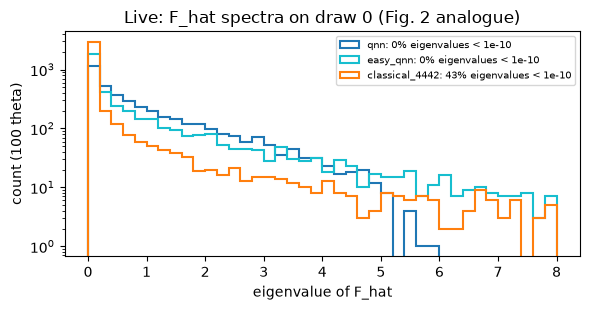

In [6]:
models = {"qnn": QNN, "easy_qnn": EASY, "classical_4442": CLASSICAL_4442}
built = {name: build_model(spec) for name, spec in models.items()}
sample = torch.as_tensor(x_iris[[0, 50, 99]], dtype=torch.float64)
for name, model in built.items():
    theta = torch.as_tensor(initial_parameters(1, model.d, [1], 0.0, 1.0)).repeat(3, 1)
    with torch.no_grad():
        probabilities = model.probabilities(sample, theta)
    print(f"{name:15s} d = {model.d}  p(class 1) on three Iris points: {probabilities[:, 1].numpy().round(3)}")

live_draw = {name: ours if name == "qnn" else fisher_for_draw(model, FISHER_CFG, 0, DEVICE)
             for name, model in built.items()}
figure, axis = plt.subplots(figsize=(6, 3.2))
bins = np.linspace(0, 8, 41)
for name, result in live_draw.items():
    axis.hist(result["eigenvalues"].ravel(), bins=bins, histtype="step", lw=1.5,
              color=color_of(name), label=f"{name}: {100 * result['spectrum']['fraction_near_zero']:.0f}% eigenvalues < 1e-10")
axis.set_yscale("log"); axis.set_xlabel("eigenvalue of F_hat"); axis.set_ylabel("count (100 theta)")
axis.set_title("Live: F_hat spectra on draw 0 (Fig. 2 analogue)"); axis.legend(fontsize=7)
plt.tight_layout(); plt.show()

**Observation.** The classical network has a large fraction of zero eigenvalues (a degenerate
Fisher); the QNN spectrum is spread out with none near zero; the easy model sits in between.
**Claim impact.** Consistent with C-02 (reproduced; the stored 5-draw result in `README.md`
gives 43% near-zero eigenvalues for the classical network).

## 6. Small live experiment: the effective dimension

We compute d_{1,n}/d for the three models on **one** draw (seed 0, 100 θ × 100 x), live. The paper
uses one draw; our stored result uses five (seeds 0-4). This live run is the reduced version.

In [7]:
live_curves = {name: effective_dimension(result["f_hat"], N_VALUES) / built[name].d
               for name, result in live_draw.items()}
for name, curve in live_curves.items():
    print(f"{name:15s} n=1e3: {curve[0]:.4f}   n=1e5: {curve[6]:.4f}   n=1e6: {curve[10]:.4f}")

qnn             n=1e3: 0.8211   n=1e5: 0.8984   n=1e6: 0.9211
easy_qnn        n=1e3: 0.6744   n=1e5: 0.7715   n=1e6: 0.8146
classical_4442  n=1e3: 0.5268   n=1e5: 0.4968   n=1e6: 0.5048


## 7. Headline reproduction result (Fig. 3a and Table 1)

**Stored**: five draws per model (`effdim_d40_original`) against the authors' published Fig. 3a
source data, and the 100-seed Table 1 training run (`training_iris_original`, paper settings).

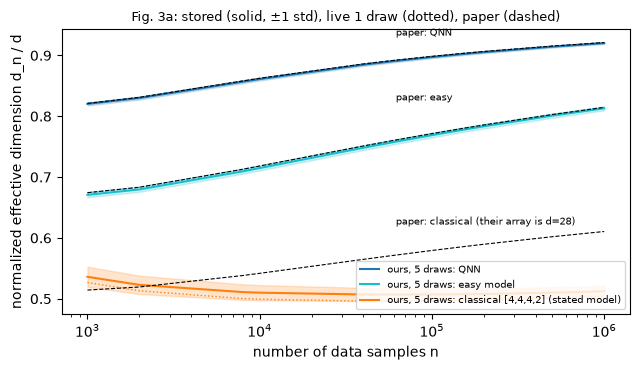

model                ours n=1e3   paper         ours n=1e6   paper
QNN          0.8203 ± 0.0025  0.8211  0.9201 ± 0.0014  0.9211
easy model   0.6708 ± 0.0039  0.6744  0.8130 ± 0.0033  0.8146
classical    0.5361 ± 0.0166  0.5143  0.5123 ± 0.0090  0.6106


In [8]:
paper = STORED["paper"]
stored = STORED["phase3"]["effdim_original"]
n_stored = np.asarray(stored["n_values"])
keep = n_stored <= 1e6
figure, axis = plt.subplots(figsize=(6.5, 3.8))
for name, label in (("qnn", "QNN"), ("easy_qnn", "easy model"), ("classical_4442", "classical [4,4,4,2] (stated model)")):
    entry = stored["models"][name]
    mean, std = np.asarray(entry["ed_mean"])[keep], np.asarray(entry["ed_std"])[keep]
    axis.plot(n_stored[keep], mean, color=color_of(name), label=f"ours, 5 draws: {label}")
    axis.fill_between(n_stored[keep], mean - std, mean + std, color=color_of(name), alpha=0.2)
    axis.plot(N_VALUES, live_curves[name], ":", color=color_of(name), lw=1)
for key, label in (("qnn", "QNN"), ("easy_qnn", "easy"), ("classical_d28_array", "classical (their array is d=28)")):
    axis.plot(paper["n_values"], paper["fig3a"][key], "k--", lw=0.8)
    axis.annotate(f"paper: {label}", (paper["n_values"][-1], paper["fig3a"][key][-1]), fontsize=7,
                  xytext=(-150, 5), textcoords="offset points")
axis.set_xscale("log"); axis.set_xlabel("number of data samples n"); axis.set_ylabel("normalized effective dimension d_n / d")
axis.set_title("Fig. 3a: stored (solid, ±1 std), live 1 draw (dotted), paper (dashed)", fontsize=9)
axis.legend(fontsize=7, loc="lower right"); plt.tight_layout(); plt.show()

rows = [("QNN", "qnn", "qnn"), ("easy model", "easy_qnn", "easy_qnn"), ("classical", "classical_4442", "classical_d28_array")]
print(f"{'model':12s} {'ours n=1e3':>18s} {'paper':>7s} {'ours n=1e6':>18s} {'paper':>7s}")
for label, ours_key, paper_key in rows:
    e = stored["models"][ours_key]
    print(f"{label:12s} {e['ed_mean'][0]:.4f} ± {e['ed_std'][0]:.4f}  {paper['fig3a'][paper_key][0]:.4f}"
          f"  {e['ed_mean'][10]:.4f} ± {e['ed_std'][10]:.4f}  {paper['fig3a'][paper_key][10]:.4f}")

In [9]:
table1 = STORED["phase3"]["training_original"]["models"]
print(f"{'model':16s} {'final loss, ours (100 seeds)':>30s} {'paper':>7s} {'Fisher-Rao, ours':>17s} {'paper':>7s}")
for name in ("qnn", "easy_qnn", "classical_41112"):
    e = table1[name]
    print(f"{name:16s} {e['final_loss_mean']:.4f} ± {e['final_loss_std']:.4f}{'':>14s} {paper['table1_loss'][name]:.4f}"
          f" {e['fisher_rao_norm_mean']:17.1f} {paper['table1_fisher_rao'][name]:7.2f}")

model              final loss, ours (100 seeds)   paper  Fisher-Rao, ours   paper
qnn              0.2316 ± 0.0079               0.2314             115.6  117.84
easy_qnn         0.4322 ± 0.0317               0.4305             109.9  104.89
classical_41112  0.3891 ± 0.1250               0.3790              63.3   46.45


**Observation.** Our QNN and easy-model curves sit on the paper's to within 0.004 at every n, and
the ordering QNN > easy > classical holds at every n. Our [4,4,4,2] curve does **not** match the
paper's classical curve: the authors' cached array behind that curve has shape 28 × 28, i.e. it
is a d = 28 network (re-deriving it reproduces their curve to 0.003). Table 1 losses match to
within 0.01 (QNN 0.2316 vs 0.2314).
**Inference.** The paper's numbers are reproduced; the classical Fig. 3a curve is mislabelled.
**Remaining uncertainty.** None material for the numbers; whether the capacity ordering *means*
better learning is tested in section 8.
**Claim impact.** C-01, C-02 **reproduced** (with the classical-curve caveat). Table 1 **numbers
reproduced**; whether they support C-04 is the next question.

## 8. Fair baseline comparison

The paper's Table 1 compares models under different conditions. A fair comparison must match
every dimension that could explain the result. For the paper's comparison and ours:

| Dimension | Paper (Table 1) | Fair comparison K1 (ours) | Matched? |
|---|---|---|---|
| Information and inputs | same 4 Iris features | same | matched |
| Parameter count | d = 8 for all | d = 8 for all | matched |
| Training data | 100 points (98 for quantum in their scripts) | 100 points for all | matched |
| Optimization steps | 100 full-batch iterations | 100 | matched |
| Optimizer | Qiskit ADAM (quantum) vs torch Adam (classical) | torch Adam for all | matched in K1 only |
| Initialization | U[0, 2π] quantum, U[0, 1] classical (all weights positive) | U[-1, 1] for all | matched in K1 only |
| Tuning budget | none: one lr (0.1) for all | 4 learning rates × 20 seeds per model | matched in K1 only |
| Compute and wall time | not reported | reported (quantum costs more) | **not matched** |
| Evaluation protocol | final training loss, 100 trials | final training loss, fresh seeds 100-199 | matched |

The paper's classical model [4,1,1,1,2] is a width-1 chain. With d = 8, 4 inputs and 2 outputs,
the only other bias-free topology is the linear softmax classifier [4,2], which we add as the
strong conventional baseline.

**Live mini-version** (20 seeds, both protocols, the two quantum models and both classical nets).

In [10]:
seeds = list(range(100, 120))
x, y = torch.as_tensor(x_iris, dtype=torch.float64), torch.as_tensor(y_iris)
D8 = {
    "qnn": {**QNN, "ansatz_reps": 1},
    "classical_41112": dict(type="classical", sizes=[4, 1, 1, 1, 2], activation="leaky_relu", head="softmax", bias=False),
    "classical_42": dict(type="classical", sizes=[4, 2], activation="leaky_relu", head="softmax", bias=False),
}
PAPER_PROTOCOL = {"qnn": ("qiskit_adam", 0.1, (0.0, 2 * math.pi)),
                  "classical_41112": ("torch_adam", 0.1, (0.0, 1.0)),
                  "classical_42": ("torch_adam", 0.1, (0.0, 1.0))}
# Learning rates selected in the stored K1 run (seeds 0-19, training loss); see the next cell.
FAIR_LR = {name: STORED["phase5"]["fair_iris01_d8"]["models"][key]["selected_lr"]
           for name, key in (("qnn", "Q2_d8"), ("classical_41112", "classical_41112"), ("classical_42", "classical_42"))}

live_final = {}
for protocol in ("paper", "fair"):
    for name, spec in D8.items():
        model = build_model(spec)
        optimizer, lr, (low, high) = PAPER_PROTOCOL[name] if protocol == "paper" else ("torch_adam", FAIR_LR[name], (-1.0, 1.0))
        theta0 = torch.as_tensor(initial_parameters(len(seeds), model.d, seeds, low, high))
        result = train(model, x, y, theta0, dict(iterations=100, lr=lr, optimizer=optimizer, gradient="autograd",
                                                  finite_difference_step=1e-10, log_every=1000))
        live_final[(protocol, name)] = result["losses"][-1]
        print(f"{protocol:5s} protocol  {name:16s} lr={lr:<5g} final training CE {result['losses'][-1].mean():.4f} ± {result['losses'][-1].std():.4f}")

paper protocol  qnn              lr=0.1   final training CE 0.2343 ± 0.0103
paper protocol  classical_41112  lr=0.1   final training CE 0.3954 ± 0.1254
paper protocol  classical_42     lr=0.1   final training CE 0.0406 ± 0.0017


fair  protocol  qnn              lr=0.3   final training CE 0.2298 ± 0.0024
fair  protocol  classical_41112  lr=0.3   final training CE 0.1437 ± 0.2276
fair  protocol  classical_42     lr=0.3   final training CE 0.0091 ± 0.0014


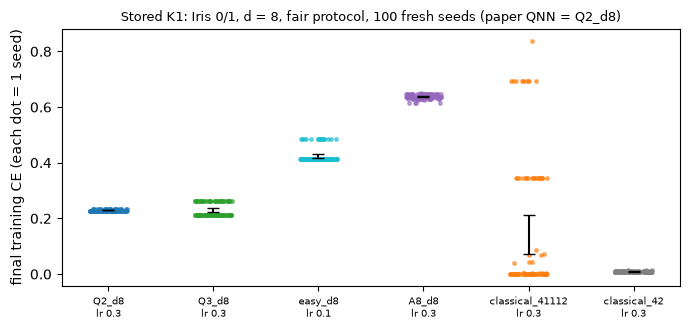

lr grid (mean final training CE, seeds 0-19):
  Q2_d8            {'0.01': 0.3187, '0.03': 0.2487, '0.1': 0.2325, '0.3': 0.2295} -> selected 0.3
  Q3_d8            {'0.01': 0.3105, '0.03': 0.2499, '0.1': 0.2381, '0.3': 0.2377} -> selected 0.3
  easy_d8          {'0.01': 0.5025, '0.03': 0.4432, '0.1': 0.4307, '0.3': 0.4343} -> selected 0.1
  A8_d8            {'0.01': 0.6559, '0.03': 0.6439, '0.1': 0.6398, '0.3': 0.6377} -> selected 0.3
  classical_41112  {'0.01': 0.6006, '0.03': 0.4229, '0.1': 0.2782, '0.3': 0.1051} -> selected 0.3
  classical_42     {'0.01': 0.4551, '0.03': 0.2121, '0.1': 0.0446, '0.3': 0.0087} -> selected 0.3
classical_42 vs Q2_d8: gap -0.2207, 3 SE 0.0009 -> first lower (resolved)
classical_41112 vs Q2_d8: gap -0.0880, 3 SE 0.0693 -> first lower (resolved)
Q2_d8 vs easy_d8: gap -0.1953, 3 SE 0.0081 -> first lower (resolved)


In [11]:
k1 = STORED["phase5"]["fair_iris01_d8"]["models"]
order = ["Q2_d8", "Q3_d8", "easy_d8", "A8_d8", "classical_41112", "classical_42"]
figure, axis = plt.subplots(figsize=(7, 3.4))
for position, name in enumerate(order):
    values = np.asarray(k1[name]["per_seed"]["train_loss"])
    jitter = np.random.RandomState(position).uniform(-0.18, 0.18, len(values))
    axis.scatter(position + jitter, values, s=6, color=color_of(name), alpha=0.6)
    axis.errorbar(position, values.mean(), yerr=3 * values.std() / np.sqrt(len(values)), color="black", capsize=4)
axis.set_xticks(range(len(order)), [f"{n}\nlr {k1[n]['selected_lr']:g}" for n in order], fontsize=7)
axis.set_ylabel("final training CE (each dot = 1 seed)")
axis.set_title("Stored K1: Iris 0/1, d = 8, fair protocol, 100 fresh seeds (paper QNN = Q2_d8)", fontsize=9)
plt.tight_layout(); plt.show()

print("lr grid (mean final training CE, seeds 0-19):")
for name in order:
    print(f"  {name:16s}", {lr: round(v, 4) for lr, v in k1[name]["grid_mean_loss"].items()}, "-> selected", k1[name]["selected_lr"])
for first, second in (("classical_42", "Q2_d8"), ("classical_41112", "Q2_d8"), ("Q2_d8", "easy_d8")):
    gap, threshold, verdict = decision(k1[first]["per_seed"]["train_loss"], k1[second]["per_seed"]["train_loss"])
    print(f"{first} vs {second}: gap {gap:+.4f}, 3 SE {threshold:.4f} -> {verdict}")

**Observation.** Under the paper's protocol (live, 20 seeds) the QNN (about 0.23) beats the paper's
[4,1,1,1,2] (about 0.40), as in Table 1, but the linear [4,2] already reaches about 0.04 **with the
paper's own learning rate and init**. Under the fair protocol the paper's chain improves to 0.14 and
the linear model to 0.009, while the QNN stays at 0.23. On the 100 stored fresh seeds both classical
gaps are resolved. Every model reaches ~100% training accuracy; the loss differences measure
confidence.
**Inference.** The paper's training advantage comes from the comparison conditions: first the
choice of a width-1 classical chain, then one untuned learning rate and an all-positive classical
init. It is not a property of the QNN relative to classical models of the same size. The QNN's loss plateaus near
0.23 because its parity output cannot become confident at depth 1.
**Remaining uncertainty.** lr 0.3, the top of the grid, was selected or tied for most models; a
larger lr could lower the classical losses further but cannot rescue the QNN (its loss changes by
< 0.003 between lr 0.1 and 0.3). Wall time is not matched: the quantum simulation is slower.
**Claim impact.** C-04 is **contradicted** under a fair comparison.

## 9. Controls and ablations

Three controls test whether the paper's *explanations* survive:

1. **Parameter domain** (paper text [-1, 1] vs code [0, 1]) for the effective dimension.
2. **Fisher-Rao norm vs initialization range** (C-05).
3. **Unnormalized Fisher scale vs qubit count** (C-03): the normalized spectrum hides it.

In [12]:
domain = STORED["phase3"]["effdim_paper_domain"]["models"]
for name in ("qnn", "easy_qnn", "classical_4442"):
    print(f"theta ~ U[-1,1]  {name:15s} d_n/d at n=1e3: {domain[name]['ed_mean'][0]:.3f}   n=1e6: {domain[name]['ed_mean'][10]:.3f}")

paper_init = STORED["phase3"]["training_original"]["models"]
same_init = STORED["phase3"]["training_paper_domain"]["models"]
print("\nFisher-Rao norm at the trained parameters (100 seeds):")
for name in ("qnn", "easy_qnn", "classical_41112"):
    print(f"  {name:16s} paper inits: {paper_init[name]['fisher_rao_norm_mean']:7.1f}   all init U[-1,1]: {same_init[name]['fisher_rao_norm_mean']:7.1f}")

theta ~ U[-1,1]  qnn             d_n/d at n=1e3: 0.819   n=1e6: 0.920
theta ~ U[-1,1]  easy_qnn        d_n/d at n=1e3: 0.668   n=1e6: 0.811
theta ~ U[-1,1]  classical_4442  d_n/d at n=1e3: 0.571   n=1e6: 0.671

Fisher-Rao norm at the trained parameters (100 seeds):
  qnn              paper inits:   115.6   all init U[-1,1]:     9.7
  easy_qnn         paper inits:   109.9   all init U[-1,1]:     6.9
  classical_41112  paper inits:    63.3   all init U[-1,1]:   259.9


QNN: tr F / d = ['0.0356', '0.00834', '0.00205', '0.000516'] -> x0.49 per qubit
easy model: tr F / d = ['0.0322', '0.00827', '0.00233', '0.000696'] -> x0.53 per qubit


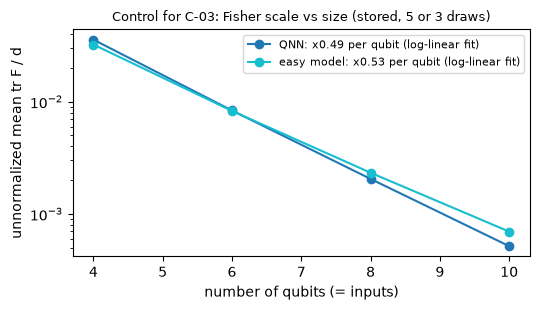

In [13]:
scaling = STORED["phase3"]["spectrum_scaling"]["models"]
base = STORED["phase3"]["effdim_original"]["models"]
figure, axis = plt.subplots(figsize=(5.5, 3.2))
for family, label in (("qnn", "QNN"), ("easy_qnn", "easy model")):
    sizes = [4, 6, 8, 10]
    entries = [base[family]] + [scaling[f"{family}_s{s}"] for s in (6, 8, 10)]
    per_parameter = [e["mean_trace"] / e["d"] for e in entries]
    slope = np.polyfit(sizes, np.log(per_parameter), 1)[0]
    print(f"{label}: tr F / d =", [f"{v:.3g}" for v in per_parameter], f"-> x{math.exp(slope):.2f} per qubit")
    axis.semilogy(sizes, per_parameter, "o-", color=color_of(family), label=f"{label}: x{math.exp(slope):.2f} per qubit (log-linear fit)")
axis.set_xlabel("number of qubits (= inputs)"); axis.set_ylabel("unnormalized mean tr F / d")
axis.set_title("Control for C-03: Fisher scale vs size (stored, 5 or 3 draws)", fontsize=9)
axis.legend(fontsize=8); plt.tight_layout(); plt.show()

**Observation.** (1) With θ ~ U[-1, 1] the ordering QNN > easy > classical still holds (the
classical network rises to about 0.57-0.67). (2) The Fisher-Rao ordering **reverses** when all
models start in U[-1, 1]: the classical norm becomes the largest. (3) Per parameter, the
unnormalized Fisher trace shrinks by about half per added qubit for both quantum models (the
fitted per-qubit factor is in the legend).
**Inference.** The capacity ordering is robust to the parameter domain. The Fisher-Rao norm tracks
‖θ‖² (the initialization scale), not capacity. The QNN's Fisher entries vanish exponentially, which
is the barren-plateau signature of Sec. 3.4, even though the normalized spectrum looks stable.
**Remaining uncertainty.** The scaling fit uses 4-10 qubits only.
**Claim impact.** C-01 **robust**; C-05 **contradicted** as a capacity statement; C-03 **weakened**
(normalized shape reproduced, barren-plateau resilience not supported).

## 10. Robustness and uncertainty: held-out tasks (extensions)

Training loss on Iris 0/1 says little about learning: the task is linearly separable and every
model reaches 100% training accuracy. The extensions (all **advantage evidence**: every baseline
ran in the same run under identical conditions) use d = 40, select the lr on validation, and
report **test** cross-entropy over 100 fresh seeds. The linear [4,2] (d = 8) is an *unmatched*
simplicity reference.

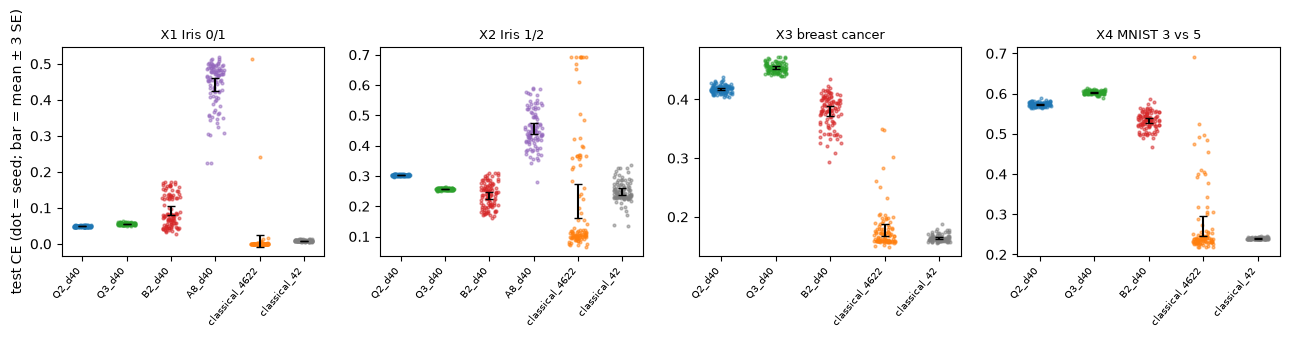

model                        X1 Iris 0/1             X2 Iris 1/2        X3 breast cancer         X4 MNIST 3 vs 5
Q2_d40             0.049 ± 0.002 (1.000)   0.303 ± 0.002 (1.000)   0.418 ± 0.007 (0.878)   0.573 ± 0.005 (0.719)
Q3_d40             0.056 ± 0.002 (1.000)   0.257 ± 0.003 (1.000)   0.454 ± 0.008 (0.863)   0.603 ± 0.004 (0.700)
B2_d40             0.092 ± 0.044 (1.000)   0.236 ± 0.040 (0.994)   0.380 ± 0.028 (0.906)   0.533 ± 0.021 (0.824)
A8_d40             0.442 ± 0.062 (1.000)   0.456 ± 0.062 (0.993)                       —                       —
classical_4622     0.008 ± 0.056 (0.995)   0.217 ± 0.188 (0.907)   0.178 ± 0.035 (0.931)   0.271 ± 0.082 (0.879)
classical_42       0.009 ± 0.002 (1.000)   0.248 ± 0.034 (0.950)   0.164 ± 0.006 (0.930)   0.240 ± 0.002 (0.879)


In [14]:
TASKS = [("fair_iris01_d40", "X1 Iris 0/1"), ("fair_iris12_d40", "X2 Iris 1/2"),
         ("fair_bcancer_d40", "X3 breast cancer"), ("fair_mnist35_d40", "X4 MNIST 3 vs 5")]
SHOW = ["Q2_d40", "Q3_d40", "B2_d40", "A8_d40", "classical_4622", "classical_42"]
figure, axes = plt.subplots(1, 4, figsize=(13, 3.3), sharey=False)
for axis, (key, title) in zip(axes, TASKS):
    models = STORED["phase5"][key]["models"]
    names = [n for n in SHOW if n in models]
    for position, name in enumerate(names):
        values = np.asarray(models[name]["per_seed"]["test_loss"])
        jitter = np.random.RandomState(position).uniform(-0.2, 0.2, len(values))
        axis.scatter(position + jitter, values, s=4, color=color_of(name), alpha=0.5)
        axis.errorbar(position, values.mean(), yerr=3 * values.std() / np.sqrt(len(values)), color="black", capsize=3)
    axis.set_xticks(range(len(names)), names, rotation=50, ha="right", fontsize=7)
    axis.set_title(title, fontsize=9)
axes[0].set_ylabel("test CE (dot = seed; bar = mean ± 3 SE)")
plt.tight_layout(); plt.show()

print(f"{'model':16s}" + "".join(f"{title:>24s}" for _, title in TASKS))
for name in SHOW:
    cells = []
    for key, _ in TASKS:
        models = STORED["phase5"][key]["models"]
        if name in models:
            loss = np.asarray(models[name]["per_seed"]["test_loss"]); accuracy = np.asarray(models[name]["per_seed"]["test_accuracy"])
            cells.append(f"{loss.mean():.3f} ± {loss.std():.3f} ({accuracy.mean():.3f})")
        else:
            cells.append("—")
    print(f"{name:16s}" + "".join(f"{c:>24s}" for c in cells))

In [15]:
# Sweep completeness: every stored comparison has the full lr grid and 100 finite fresh seeds.
for key, block in STORED["phase5"].items():
    grid = block["comparison"]["lr_grid"]
    for name, entry in block["models"].items():
        assert len(entry["grid_mean_loss"]) == len(grid), (key, name)
        for values in entry["per_seed"].values():
            assert len(values) == block["comparison"]["final_seeds"]["count"] and np.all(np.isfinite(values)), (key, name)
print("All stored comparisons complete:", {key: len(block["models"]) for key, block in STORED["phase5"].items()}, "models, 100 seeds each")
print("Decisions on test CE (100 fresh seeds each):")
for key, title in TASKS:
    models = STORED["phase5"][key]["models"]
    best_classical = min(("classical_4622", "classical_42"), key=lambda n: np.mean(models[n]["per_seed"]["test_loss"]))
    best_qubit = min(("Q2_d40", "Q3_d40"), key=lambda n: np.mean(models[n]["per_seed"]["test_loss"]))
    for first, second in ((best_qubit, best_classical), ("B2_d40", best_qubit), ("B2_d40", best_classical)):
        gap, threshold, verdict = decision(models[first]["per_seed"]["test_loss"], models[second]["per_seed"]["test_loss"])
        print(f"  {title:18s} {first:15s} vs {second:15s} gap {gap:+.4f} (3 SE {threshold:.4f}) -> {verdict}")

All stored comparisons complete: {'fair_iris01_d8': 6, 'fair_iris01_d40': 6, 'fair_iris12_d40': 6, 'fair_bcancer_d40': 5, 'fair_mnist35_d40': 5} models, 100 seeds each
Decisions on test CE (100 fresh seeds each):
  X1 Iris 0/1        Q2_d40          vs classical_4622  gap +0.0406 (3 SE 0.0168) -> second lower (resolved)
  X1 Iris 0/1        B2_d40          vs Q2_d40          gap +0.0435 (3 SE 0.0131) -> second lower (resolved)
  X1 Iris 0/1        B2_d40          vs classical_4622  gap +0.0841 (3 SE 0.0213) -> second lower (resolved)
  X2 Iris 1/2        Q3_d40          vs classical_4622  gap +0.0399 (3 SE 0.0565) -> no resolved difference
  X2 Iris 1/2        B2_d40          vs Q3_d40          gap -0.0207 (3 SE 0.0119) -> first lower (resolved)
  X2 Iris 1/2        B2_d40          vs classical_4622  gap +0.0193 (3 SE 0.0578) -> no resolved difference
  X3 breast cancer   Q2_d40          vs classical_42    gap +0.2538 (3 SE 0.0026) -> second lower (resolved)
  X3 breast cancer   B2_d40

**Observation.** On every held-out task, a classical model (the d = 40 network or even the
8-parameter linear model) has the lowest or a tied-lowest test loss. The qubit QNNs lose to the
classical models on X1, X3, X4 and tie the best classical model only on X2 (ZZ×3). Seed-to-seed
spread is small for the quantum models and larger for [4,6,2,2], which has a few bad seeds.
**Inference.** No quantum model shows a learning advantage under matched parameters, data,
iterations and tuning. Higher capacity (section 7) does not translate into lower held-out loss.
**Remaining uncertainty.** One fixed split per task (split variance is not captured); Iris test
sets have 20 points; X3/X4 are reduced to 4 PCA features (MNIST keeps 34% of its variance); 100
iterations for all models, with some quantum losses still falling slowly.
**Claim impact.** Extends the C-04 verdict: no evidence of a trainability or generalization
advantage for the paper's QNN on any task tested.

## 11. Photonic assessment (extension, MerLin)

**Goal.** Does the paper's question carry over to linear optics? The adaptation does **not** map
qubit gates one-to-one (dual-rail CNOTs cost extra modes and photons). Instead it is a native
interferometric classifier (`lib/photonic_merlin.py`):

- m optical modes with m/2 photons; input either a Fock state [1,0,1,0,...] or a linear-cluster
  state emitted by one spin (`ML.EmitterState`, emitter measured in the X basis);
- the paper's data map as phases (2x_i and 2(π−x_i)(π−x_{i+1})) between fixed mixers, re-uploaded
  3 times between blocks of a trainable MZI mesh with exactly d = 40 phases;
- readout: parity of threshold-detector clicks on the odd modes; exact simulation (FOCK space).

Two designs matter: **A8** (10 modes / 5 photons, cluster input), selected for the highest
effective dimension; and **B2** (6 modes / 3 photons, cluster input), selected later for capacity
*and* validation loss together. The live cells below need a MerLin build with `EmitterState`
(the local photonic_engines fork); otherwise they fall back to stored results only.

In [16]:
try:
    import merlin as ML
    HAS_EMITTER = hasattr(ML, "EmitterState")
except ImportError:
    HAS_EMITTER = False
PHOTONIC = dict(type="photonic", n_inputs=4, encoding="hard", d=40, detection="threshold", mesh_order="ps_bs",
                layout="interleaved", input_kind="cluster", readout="click_parity", data_reps=3)
B2, A8 = {**PHOTONIC, "extra_modes": 2}, {**PHOTONIC, "extra_modes": 6}
print("MerLin EmitterState available:", HAS_EMITTER)
if HAS_EMITTER:
    for name, spec in (("B2", B2), ("A8", A8)):
        model = build_model(spec)
        print(f"{name}: {json.dumps(model.describe())[:260]} ...")

MerLin EmitterState available: True
B2: {"computation_space": "FOCK", "detector_model": "ideal threshold (clicks; bunched events kept)", "photons": 3, "modes": 6, "input_state": "cluster state of 3 photons from one spin emitter (EmitterState.caterpillar, photon k on modes (2k, 2k+1); emitter measure ...
A8: {"computation_space": "FOCK", "detector_model": "ideal threshold (clicks; bunched events kept)", "photons": 5, "modes": 10, "input_state": "cluster state of 5 photons from one spin emitter (EmitterState.caterpillar, photon k on modes (2k, 2k+1); emitter measur ...


**Live margin diagnostic.** Effective dimension counts parameter directions; it says nothing about
how *confident* the output can become. For one Iris point we let each design optimize all 40
phases to maximize p(correct class), from 4 random starts. A design that cannot reach p ≈ 1 has a
cross-entropy floor whatever its capacity.

In [17]:
def best_probability(spec, x_point, target, starts=4, steps=150):
    model = build_model(spec)
    theta = (torch.rand(starts, model.d, dtype=torch.float64, generator=torch.Generator().manual_seed(0)) * 2 - 1).requires_grad_(True)
    optimizer = torch.optim.Adam([theta], lr=0.1)
    inputs = x_point.repeat(starts, 1)
    for _ in range(steps):
        optimizer.zero_grad()
        loss = -torch.log(model.probabilities(inputs, theta)[:, target]).sum()
        loss.backward(); optimizer.step()
    with torch.no_grad():
        return model.probabilities(inputs, theta)[:, target].max().item()


if HAS_EMITTER:
    point = torch.as_tensor(x_iris[60:61], dtype=torch.float64)  # an Iris class-1 point
    for name, spec in (("B2 (6 modes, cluster)", B2), ("A8 (10 modes, cluster)", A8),
                       ("10 modes, Fock input", {**A8, "input_kind": "fock"}), ("qubit QNN", QNN)):
        started = time.perf_counter()
        print(f"{name:24s} max p(correct class) = {best_probability(spec, point, 1):.4f}   ({time.perf_counter() - started:.0f} s)")
else:
    print("Skipped (no EmitterState). Stored result (LOG.md Amendment 5): A8 0.78-0.81; 10-mode Fock 0.997-0.999; 6-mode and qubit 1.000.")

B2 (6 modes, cluster)    max p(correct class) = 1.0000   (1 s)


A8 (10 modes, cluster)   max p(correct class) = 0.7512   (1 s)


10 modes, Fock input     max p(correct class) = 0.9886   (0 s)


qubit QNN                max p(correct class) = 1.0000   (1 s)


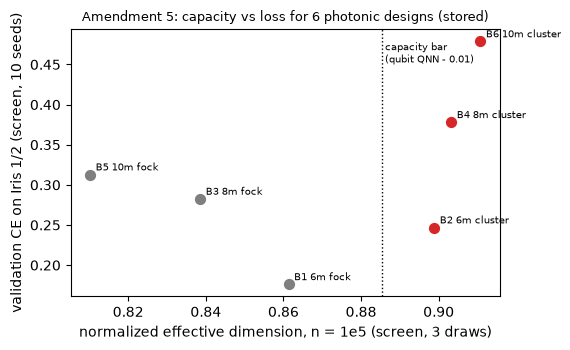

Effective dimension on fresh draws 10-14 (n = 1e3 / 1e5 / 1e6):
  B2                 0.8467 ± 0.0008 / 0.8970 ± 0.0007 / 0.9142 ± 0.0006
  A8                 0.8455 ± 0.0016 / 0.9096 ± 0.0018 / 0.9295 ± 0.0015
  qubit QNN, ZZ x3   0.8137 ± 0.0024 / 0.8926 ± 0.0011 / 0.9165 ± 0.0008
  qubit QNN, ZZ x2   0.8177 ± 0.0023 / 0.8952 ± 0.0012 / 0.9186 ± 0.0009


In [18]:
screen_ed = STORED["phase4"]["a5_capacity_screen"]["models"]
screen_loss = STORED["phase4"]["a5_loss_screen"]["models"]
bar = screen_ed["Q3_qubit_qnn_reps3"]["ed_mean"][6] - 0.01
figure, axis = plt.subplots(figsize=(5.8, 3.6))
for name, entry in screen_loss.items():
    capacity = screen_ed[name]["ed_mean"][6]
    loss = min(entry["grid_mean_loss"].values())
    axis.scatter(capacity, loss, s=50, color="tab:red" if "cluster" in name else "tab:gray")
    axis.annotate(name.replace("_", " "), (capacity, loss), fontsize=7, xytext=(4, 3), textcoords="offset points")
axis.axvline(bar, color="black", ls=":", lw=1)
axis.text(bar, axis.get_ylim()[1] * 0.97, " capacity bar\n (qubit QNN - 0.01)", fontsize=7, va="top")
axis.set_xlabel("normalized effective dimension, n = 1e5 (screen, 3 draws)")
axis.set_ylabel("validation CE on Iris 1/2 (screen, 10 seeds)")
axis.set_title("Amendment 5: capacity vs loss for 6 photonic designs (stored)", fontsize=9)
plt.tight_layout(); plt.show()

confirm = STORED["phase4"]["a5_capacity_confirm"]["models"]
a4 = STORED["phase4"]["a4_confirm_u01"]["models"]
print("Effective dimension on fresh draws 10-14 (n = 1e3 / 1e5 / 1e6):")
for label, entry in (("B2", confirm["B2_6m_cluster"]), ("A8", a4["A8_10m_cluster_reps3"]),
                     ("qubit QNN, ZZ x3", confirm["Q3_qubit_qnn_reps3"]), ("qubit QNN, ZZ x2", a4["Q2_qubit_qnn"])):
    print(f"  {label:18s}", " / ".join(f"{entry['ed_mean'][i]:.4f} ± {entry['ed_std'][i]:.4f}" for i in (0, 6, 10)))

**Observation.**
- A8 has the highest effective dimension of all models (0.910 at n = 1e5, above the qubit QNN's
  0.893-0.895 by more than 3 std), but even for a single input it cannot push p(correct class)
  much above 0.75-0.8 (live: 4 starts x 150 steps; stored: 0.78-0.81 with 8 starts x 200 steps).
  The same chip with a Fock input reaches about 0.99, and the 6-mode chip and the qubit QNN reach 1.
- Across the six designs, more modes or a cluster input raise capacity and raise the loss floor:
  a capacity-versus-loss trade-off. B2 is the lowest-loss design that clears the capacity bar.
- In section 10, A8 has the worst held-out loss on every task; B2 beats both qubit QNNs on X2, X3
  and X4 (MNIST accuracy 0.824 vs 0.719), loses to them on the easy X1, and trails the classical
  models everywhere except a tie on X2.

**Inference.** A native photonic model reaches qubit-level (or higher) capacity, but capacity
optimized alone selects a poor learner. Selecting on capacity and loss together gives the best
quantum learner tested here, and that result held on two tasks it was never selected on (X3, X4).

**Remaining uncertainty.** Ideal lossless photons and an ideal emitter; one readout family
(click parity); the six designs were chosen by hand; exact simulation only, no hardware.

**Claim impact (extension).** A photonic implementation of the paper's idea is feasible in MerLin
and is the strongest *quantum* learner here, but it shows **no advantage over classical baselines**.

## 12. Conclusion and limitations

**What reproduced** (numbers match the paper within the observed spread):
- the effective-dimension curves of the QNN and the easy model, and the ordering
  QNN > easy > classical at every n (C-01; sections 6-7);
- the Fisher spectra: degenerate classical, uniform QNN; our F̂ equals the authors' arrays (C-02;
  sections 4-5);
- Table 1 training losses and Fisher-Rao norms (section 7); Fig. 6 and the large-n limit (stored,
  `README.md`).

**What did not reproduce:**
- the published classical Fig. 3a curve: it comes from a d = 28 network, not the stated d = 40 one
  (section 7);
- the trainability claim C-04: under a fair, per-model-tuned comparison both d = 8 classical nets
  train to lower loss than the QNN (section 8);
- C-05 as a capacity statement: the Fisher-Rao ordering reverses with the init range (section 9).

**What remains unresolved:**
- *why* the quantum models trail classical baselines; the proposed ablations (trainable output
  scaling, trainable input weights, longer training) were not run (`LOG.md`);
- split-to-split variability of the held-out comparisons (section 10).

**What was not attempted:** the IBM hardware run (no QPU access); a numerical test of the
generalization bound (unspecified constants); photonic hardware runs.

**Separating the outcomes:**
- the software executes, and every component check passes (section 4);
- the paper's metrics reproduce (sections 6-7);
- the paper's explanations partly survive controls: capacity yes, barren-plateau resilience and
  the Fisher-Rao interpretation no (section 9);
- the method does **not** beat a fair classical baseline on any task tested (sections 8, 10).

**Reductions and deviations to keep in mind:** live cells use one draw and 20 seeds (the stored
results use 5 draws and 100 seeds); exact autograd instead of parameter-shift and finite
differences; all models use 100 Iris points (the authors' quantum scripts used 98); the fair
protocol deliberately departs from the paper's single learning rate, optimizers and inits;
X3/X4 inputs are reduced to 4 PCA features.

**Reproduction verdict: partially reproduced.** The numbers reproduce; the capacity claim
holds; the barren-plateau and Fisher-Rao interpretations are not supported; the trainability
claim fails against fair baselines.

**Photonic verdict (extension):** `MERLIN_IMPLEMENTATION`. A native MerLin classifier with an
emitter cluster-state input matches the qubit QNN's capacity and, when selected for capacity and
loss together (B2), learns better than the qubit QNN on three of four held-out tasks; no quantum
model, photonic or qubit, beats the classical baselines (section 11).

In [19]:
print(f"Notebook run time: {time.perf_counter() - NOTEBOOK_START:.0f} s on CPU")

Notebook run time: 8 s on CPU
